# Notebook 05 — Shadow Model Membership Inference Attack
**DS Lab 2 Extension | Black-Box MIA in Federated Learning**

This notebook implements the **shadow model attack** (Shokri et al., 2017), which is a realistic
black-box membership inference attack that does **not** require the attacker to access real training data.

## Why shadow models?

In the base experiments (Notebooks 01–02), the attacker built their attack dataset using:
- **Members**: real samples from the FL training set (x_train)
- **Non-members**: real samples from the FL test set (x_test)

This is **unrealistic** in federated learning. Training data never leaves the client devices.
A real attacker cannot access x_train.

The shadow model approach solves this:
1. The attacker obtains **similar but different data** (shadow dataset — same domain, different samples)
2. The attacker trains their own **shadow FL model** on this shadow dataset
3. Because the attacker controls the shadow model, they know which samples are members and which are not
4. They use the shadow model's predictions to **train the attack classifier**
5. The trained attack classifier is then applied to the **real target FL model**

## Shadow data choice

The target FL model is trained on **CIFAR-10** (10 classes, 50,000 samples).
The shadow dataset is **CIFAR-100** — same image format (32×32 RGB), same domain (natural images),
but completely different classes and samples. This satisfies Kiss Péter's requirement:
**similar data, not the same**.

## What this notebook does
- Trains the target FL model on CIFAR-10 (same as Notebook 01)
- Trains a shadow FL model on CIFAR-100 (attacker's surrogate)
- Builds attack training data from shadow model predictions
- Trains and evaluates the attack classifier on the real target model
- Compares shadow model attack AUC vs the unrealistic baseline from Notebook 01
- Evaluates across IID and Non-IID conditions

In [ ]:
# ── 1. Imports & Configuration ────────────────────────────────────────────────
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score, accuracy_score, precision_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.metrics import roc_curve
import os, json, warnings
warnings.filterwarnings('ignore')

# Output directory
OUTPUT_DIR = '/content/outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── Configuration ─────────────────────────────────────────────────────────────
RANDOM_SEED   = 42
NUM_CLIENTS   = 5
NUM_ROUNDS    = 10
LOCAL_EPOCHS  = 3
BATCH_SIZE    = 64
LEARNING_RATE = 0.001

# Shadow model configuration (same architecture, shorter training for speed)
SHADOW_CLIENTS      = 5
SHADOW_ROUNDS       = 10
SHADOW_LOCAL_EPOCHS = 3

# Attack configuration
N_ATTACK_SHADOW = 5000   # shadow samples used to train attack classifier
N_ATTACK_EVAL   = 5000   # target samples used to evaluate attack

tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
print('Configuration ready.')

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Configuration ready.


In [ ]:
# ── 2. Load Both Datasets ─────────────────────────────────────────────────────
print('Loading CIFAR-10 (target FL training data)...')
(x_train_10, y_train_10), (x_test_10, y_test_10) = keras.datasets.cifar10.load_data()
x_train_10 = x_train_10.astype('float32') / 255.0
x_test_10  = x_test_10.astype('float32')  / 255.0
y_train_10 = y_train_10.flatten()
y_test_10  = y_test_10.flatten()
print(f'  CIFAR-10 train: {x_train_10.shape}, test: {x_test_10.shape}')

print('Loading CIFAR-100 (shadow dataset — similar domain, different classes)...')
(x_train_100, y_train_100), (x_test_100, y_test_100) = keras.datasets.cifar100.load_data()
x_train_100 = x_train_100.astype('float32') / 255.0
x_test_100  = x_test_100.astype('float32')  / 255.0
y_train_100 = y_train_100.flatten()
y_test_100  = y_test_100.flatten()
print(f'  CIFAR-100 train: {x_train_100.shape}, test: {x_test_100.shape}')

print()
print('Note: CIFAR-100 is the shadow dataset.')
print('Same image format (32x32 RGB), same domain (natural images),')
print('but completely different 100 classes — similar data, NOT the same.')

Loading CIFAR-10 (target FL training data)...
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 860s 5us/step
  CIFAR-10 train: (50000, 32, 32, 3), test: (10000, 32, 32, 3)
Loading CIFAR-100 (shadow dataset — similar domain, different classes)...
169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 685s 4us/step
  CIFAR-100 train: (50000, 32, 32, 3), test: (10000, 32, 32, 3)

Note: CIFAR-100 is the shadow dataset.
Same image format (32x32 RGB), same domain (natural images),
but completely different 100 classes — similar data, NOT the same.


In [ ]:
# ── 3. Helper Functions ───────────────────────────────────────────────────────

def partition_data_iid(x, y, num_clients, seed=42):
    """Shuffle and split data equally across clients (IID)."""
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(x))
    splits = np.array_split(indices, num_clients)
    client_data    = [(x[idx], y[idx]) for idx in splits]
    client_indices = [idx.tolist() for idx in splits]
    return client_data, client_indices


def partition_data_noniid(x, y, num_clients, classes_per_client, seed=42):
    """Class-based cyclic Non-IID partitioning."""
    rng = np.random.default_rng(seed)
    num_classes = len(np.unique(y))
    class_indices = {c: np.where(y == c)[0] for c in range(num_classes)}
    for c in class_indices:
        class_indices[c] = rng.permutation(class_indices[c])
    client_indices = [[] for _ in range(num_clients)]
    for i in range(num_clients):
        assigned = [(i * classes_per_client + j) % num_classes
                    for j in range(classes_per_client)]
        for c in assigned:
            client_indices[i].extend(class_indices[c].tolist())
    client_data = [(x[idx], y[idx]) for idx in client_indices]
    return client_data, client_indices


def build_model(num_classes=10, learning_rate=0.001):
    """Small CNN — same architecture as Notebooks 01 and 02."""
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(),
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax'),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


def fedavg_aggregate(client_weights, client_sizes):
    """Weighted average of client model weights."""
    total = sum(client_sizes)
    averaged = []
    for layers_weights in zip(*client_weights):
        averaged.append(
            sum(w * (n / total) for w, n in zip(layers_weights, client_sizes))
        )
    return averaged


def local_train(global_weights, x_client, y_client,
                local_epochs, batch_size, lr, num_classes=10):
    """Train a local client model and return updated weights."""
    model = build_model(num_classes=num_classes, learning_rate=lr)
    model.set_weights(global_weights)
    model.fit(x_client, y_client,
              epochs=local_epochs, batch_size=batch_size, verbose=0)
    return model.get_weights()


def run_fedavg(client_data, client_sizes, num_rounds, local_epochs,
               batch_size, lr, x_val, y_val, num_classes=10, label=''):
    """Run full FedAvg training and return trained model + round accuracies."""
    global_model   = build_model(num_classes=num_classes, learning_rate=lr)
    global_weights = global_model.get_weights()
    round_accs = []
    for r in range(1, num_rounds + 1):
        cw_list = [
            local_train(global_weights, xc, yc, local_epochs,
                        batch_size, lr, num_classes)
            for xc, yc in client_data
        ]
        global_weights = fedavg_aggregate(cw_list, client_sizes)
        global_model.set_weights(global_weights)
        _, acc = global_model.evaluate(x_val, y_val, verbose=0)
        round_accs.append(acc)
        print(f'  {label} Round {r:2d}/{num_rounds} — acc: {acc:.4f}')
    return global_model, round_accs


def get_softmax_and_loss(model, x, y):
    """Return softmax probabilities and per-sample cross-entropy loss."""
    probs = model.predict(x, batch_size=256, verbose=0)
    # per-sample cross-entropy loss (negative log-likelihood of true class)
    losses = -np.log(probs[np.arange(len(y)), y.astype(int)] + 1e-10)
    return probs, losses


def evaluate_attack(attack_clf, X_eval, y_eval):
    """Evaluate attack classifier and return metrics dict."""
    y_scores = attack_clf.predict_proba(X_eval)[:, 1]
    y_pred   = attack_clf.predict(X_eval)
    return {
        'auc':       roc_auc_score(y_eval, y_scores),
        'accuracy':  accuracy_score(y_eval, y_pred),
        'precision': precision_score(y_eval, y_pred, zero_division=0),
        'recall':    recall_score(y_eval, y_pred, zero_division=0),
        'y_scores':  y_scores,
        'y_eval':    y_eval,
    }


def loss_based_auc(losses_members, losses_nonmembers):
    """Compute AUC for loss-based attack (lower loss = more likely member)."""
    scores = np.concatenate([-losses_members, -losses_nonmembers])
    labels = np.array([1]*len(losses_members) + [0]*len(losses_nonmembers))
    return roc_auc_score(labels, scores)


print('Helper functions defined.')

Helper functions defined.


## Step 1 — Train the Target FL Model on CIFAR-10

This is the model the attacker is trying to attack.
It is trained exactly as in Notebook 01 — FedAvg, 5 clients, 10 rounds, IID partitioning.

In [ ]:
# ── Step 1: Train Target FL Model (CIFAR-10, IID) ────────────────────────────
print('Step 1: Training TARGET FL model on CIFAR-10 (IID, 5 clients, 10 rounds)...')
print('This is the model the attacker wants to attack.\n')

target_client_data, target_client_indices = partition_data_iid(
    x_train_10, y_train_10, NUM_CLIENTS, RANDOM_SEED
)
target_client_sizes   = [len(xc) for xc, _ in target_client_data]
target_member_indices = [i for sub in target_client_indices for i in sub]

target_model, target_round_accs = run_fedavg(
    target_client_data, target_client_sizes,
    NUM_ROUNDS, LOCAL_EPOCHS, BATCH_SIZE, LEARNING_RATE,
    x_test_10, y_test_10,
    num_classes=10, label='[TARGET]'
)

target_global_acc = target_round_accs[-1]
print(f'\nTarget FL model final accuracy: {target_global_acc:.4f}')

Step 1: Training TARGET FL model on CIFAR-10 (IID, 5 clients, 10 rounds)...
This is the model the attacker wants to attack.

  [TARGET] Round  1/10 — acc: 0.4674
  [TARGET] Round  2/10 — acc: 0.6099
  [TARGET] Round  3/10 — acc: 0.6569
  [TARGET] Round  4/10 — acc: 0.6797
  [TARGET] Round  5/10 — acc: 0.6937
  [TARGET] Round  6/10 — acc: 0.7078
  [TARGET] Round  7/10 — acc: 0.7174
  [TARGET] Round  8/10 — acc: 0.7178
  [TARGET] Round  9/10 — acc: 0.7219
  [TARGET] Round 10/10 — acc: 0.7246

Target FL model final accuracy: 0.7246


## Step 2 — Train the Shadow FL Model on CIFAR-100

The attacker does NOT have access to CIFAR-10 training data.
Instead, they use CIFAR-100 — **similar domain (32×32 natural images), completely different classes**.

The attacker trains their own federated model on CIFAR-100 using the **same architecture and same
FedAvg setup** as the target. Because the attacker controls this shadow training, they know
exactly which samples are shadow members and which are shadow non-members.

In [ ]:
# ── Step 2: Train Shadow FL Model (CIFAR-100, IID) ───────────────────────────
print('Step 2: Training SHADOW FL model on CIFAR-100...')
print('Attacker uses similar-domain data (32x32 RGB images) but different classes.\n')

shadow_client_data, shadow_client_indices = partition_data_iid(
    x_train_100, y_train_100, SHADOW_CLIENTS, RANDOM_SEED + 1
)
shadow_client_sizes   = [len(xc) for xc, _ in shadow_client_data]
shadow_member_indices = [i for sub in shadow_client_indices for i in sub]

shadow_model, shadow_round_accs = run_fedavg(
    shadow_client_data, shadow_client_sizes,
    SHADOW_ROUNDS, SHADOW_LOCAL_EPOCHS, BATCH_SIZE, LEARNING_RATE,
    x_test_100, y_test_100,
    num_classes=100, label='[SHADOW]'
)

shadow_global_acc = shadow_round_accs[-1]
print(f'\nShadow FL model final accuracy: {shadow_global_acc:.4f}')
print('(Lower expected — CIFAR-100 has 100 classes, harder task)')

Step 2: Training SHADOW FL model on CIFAR-100...
Attacker uses similar-domain data (32x32 RGB images) but different classes.

  [SHADOW] Round  1/10 — acc: 0.0996
  [SHADOW] Round  2/10 — acc: 0.2332
  [SHADOW] Round  3/10 — acc: 0.2916
  [SHADOW] Round  4/10 — acc: 0.3204
  [SHADOW] Round  5/10 — acc: 0.3427
  [SHADOW] Round  6/10 — acc: 0.3579
  [SHADOW] Round  7/10 — acc: 0.3688
  [SHADOW] Round  8/10 — acc: 0.3761
  [SHADOW] Round  9/10 — acc: 0.3808
  [SHADOW] Round 10/10 — acc: 0.3841

Shadow FL model final accuracy: 0.3841
(Lower expected — CIFAR-100 has 100 classes, harder task)


## Step 3 — Build Attack Training Data from the Shadow Model

The attacker queries their shadow model on:
- **Shadow members** (samples the shadow model was trained on) → label 1
- **Shadow non-members** (samples the shadow model never saw) → label 0

The softmax output of the shadow model for each sample becomes the attack feature vector.
This is the attack classifier's training data.

In [ ]:
# ── Step 3: Build Attack Training Data from Shadow Model ─────────────────────
print('Step 3: Building attack training data from shadow model predictions...')

rng = np.random.default_rng(RANDOM_SEED)

# Shadow members: samples the shadow FL model was trained on
shadow_m_idx  = rng.choice(shadow_member_indices, size=N_ATTACK_SHADOW, replace=False)
# Shadow non-members: CIFAR-100 test samples the shadow model never saw
shadow_nm_idx = rng.choice(len(x_test_100), size=N_ATTACK_SHADOW, replace=False)

print('  Querying shadow model on shadow member samples...')
shadow_m_probs, shadow_m_losses  = get_softmax_and_loss(
    shadow_model, x_train_100[shadow_m_idx], y_train_100[shadow_m_idx]
)

print('  Querying shadow model on shadow non-member samples...')
shadow_nm_probs, shadow_nm_losses = get_softmax_and_loss(
    shadow_model, x_test_100[shadow_nm_idx], y_test_100[shadow_nm_idx]
)

# Attack training data: shadow model softmax outputs
X_attack_train = np.vstack([shadow_m_probs, shadow_nm_probs])
y_attack_train = np.array([1]*N_ATTACK_SHADOW + [0]*N_ATTACK_SHADOW)

print(f'\nAttack training data (from shadow model):')
print(f'  Shape: {X_attack_train.shape}')
print(f'  Shadow members:     {N_ATTACK_SHADOW}')
print(f'  Shadow non-members: {N_ATTACK_SHADOW}')
print(f'  Feature dim: {X_attack_train.shape[1]} (shadow model has 100 output classes)')

Step 3: Building attack training data from shadow model predictions...
  Querying shadow model on shadow member samples...
  Querying shadow model on shadow non-member samples...

Attack training data (from shadow model):
  Shape: (10000, 100)
  Shadow members:     5000
  Shadow non-members: 5000
  Feature dim: 100 (shadow model has 100 output classes)


## Step 4 — Train the Attack Classifier on Shadow Data

The logistic regression attack classifier is trained **entirely on shadow model outputs** —
no real target training data is used at any point.

In [ ]:
# ── Step 4: Train Attack Classifier on Shadow Data ───────────────────────────
print('Step 4: Training attack classifier on shadow model outputs...')
print('(No target training data used — attacker only has shadow data)\n')

attack_clf_shadow = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
attack_clf_shadow.fit(X_attack_train, y_attack_train)

# Validate on held-out shadow data
X_shadow_val = np.vstack([shadow_m_probs[:500], shadow_nm_probs[:500]])
y_shadow_val = np.array([1]*500 + [0]*500)
shadow_val_auc = roc_auc_score(y_shadow_val,
    attack_clf_shadow.predict_proba(X_shadow_val)[:, 1])

print(f'Attack classifier AUC on shadow validation data: {shadow_val_auc:.4f}')
print('(This measures how well the classifier learned from shadow model patterns)')

Step 4: Training attack classifier on shadow model outputs...
(No target training data used — attacker only has shadow data)

Attack classifier AUC on shadow validation data: 0.5585
(This measures how well the classifier learned from shadow model patterns)


## Step 5 — Transfer Attack to the Real Target FL Model

**Critical step**: the shadow model (100 classes) and the target model (10 classes) produce
softmax vectors of different dimensions. The attack classifier was trained on 100-dimensional vectors.

To handle this, we extract **dimension-agnostic features** from the softmax output:
- Max confidence
- Entropy of the distribution
- Top-3 confidence values
- Prediction loss (negative log-likelihood of predicted class)

These features capture the **same membership signal** regardless of the number of output classes,
and allow the attack to transfer from the shadow model to the target model.

In [ ]:
# ── Step 5: Feature Extraction for Cross-Architecture Transfer ────────────────

def extract_features(probs):
    """
    Extract architecture-agnostic membership signal features from softmax output.
    Works regardless of the number of output classes.

    Features:
    - max_conf:   maximum confidence score (most confident class)
    - entropy:    Shannon entropy of the distribution (lower = more confident)
    - top3:       top-3 confidence values (captures confidence spread)
    - loss_proxy: negative log of max confidence (proxy for prediction loss)
    """
    max_conf   = probs.max(axis=1, keepdims=True)
    entropy    = (-probs * np.log(probs + 1e-10)).sum(axis=1, keepdims=True)
    top3       = np.sort(probs, axis=1)[:, -3:]  # top 3 confidence values
    loss_proxy = -np.log(max_conf + 1e-10)
    return np.hstack([max_conf, entropy, top3, loss_proxy])


print('Step 5: Extracting architecture-agnostic features...')
print()

# Re-build attack training data using extracted features
X_attack_train_feat = np.vstack([
    extract_features(shadow_m_probs),
    extract_features(shadow_nm_probs)
])
print(f'Feature matrix shape (shadow): {X_attack_train_feat.shape}')
print(f'Features per sample: {X_attack_train_feat.shape[1]}')
print(f'  [max_conf, entropy, top3_conf_1, top3_conf_2, top3_conf_3, loss_proxy]')

# Retrain attack classifier on extracted features
attack_clf = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
attack_clf.fit(X_attack_train_feat, y_attack_train)
print('\nAttack classifier retrained on extracted features.')

Step 5: Extracting architecture-agnostic features...

Feature matrix shape (shadow): (10000, 6)
Features per sample: 6
  [max_conf, entropy, top3_conf_1, top3_conf_2, top3_conf_3, loss_proxy]

Attack classifier retrained on extracted features.


In [ ]:
# ── Step 6: Evaluate Shadow Model Attack on Real Target FL Model ──────────────
print('Step 6: Applying shadow model attack to the REAL TARGET FL model...')
print('(Target model was trained on CIFAR-10 — attacker never saw this data)\n')

rng = np.random.default_rng(RANDOM_SEED + 10)

# Target members: real CIFAR-10 training samples (these are the actual members)
target_m_idx  = rng.choice(target_member_indices, size=N_ATTACK_EVAL, replace=False)
# Target non-members: CIFAR-10 test samples
target_nm_idx = rng.choice(len(x_test_10), size=N_ATTACK_EVAL, replace=False)

print('  Querying target model on target member samples...')
target_m_probs, target_m_losses  = get_softmax_and_loss(
    target_model, x_train_10[target_m_idx], y_train_10[target_m_idx]
)

print('  Querying target model on target non-member samples...')
target_nm_probs, target_nm_losses = get_softmax_and_loss(
    target_model, x_test_10[target_nm_idx], y_test_10[target_nm_idx]
)

# Build evaluation set using extracted features from TARGET model outputs
X_eval_target = np.vstack([
    extract_features(target_m_probs),
    extract_features(target_nm_probs)
])
y_eval_target = np.array([1]*N_ATTACK_EVAL + [0]*N_ATTACK_EVAL)

# Evaluate shadow model attack
shadow_attack_metrics = evaluate_attack(attack_clf, X_eval_target, y_eval_target)

# Also compute loss-based AUC as reference
loss_auc = loss_based_auc(target_m_losses, target_nm_losses)

print()
print('═' * 62)
print('SHADOW MODEL ATTACK RESULTS — CIFAR-10 Target (IID)')
print('═' * 62)
print(f'  Target model global accuracy : {target_global_acc:.4f}')
print(f'  Shadow model accuracy        : {shadow_global_acc:.4f}  (CIFAR-100)')
print()
print(f'  Shadow MIA AUC    : {shadow_attack_metrics["auc"]:.4f}  (random chance = 0.50)')
print(f'  Shadow MIA Recall : {shadow_attack_metrics["recall"]:.4f}')
print(f'  Shadow MIA Acc    : {shadow_attack_metrics["accuracy"]:.4f}')
print()
print(f'  Loss-based AUC (reference) : {loss_auc:.4f}')
print('  (Loss-based uses no shadow data — direct comparison baseline)')
print('═' * 62)

Step 6: Applying shadow model attack to the REAL TARGET FL model...
(Target model was trained on CIFAR-10 — attacker never saw this data)

  Querying target model on target member samples...
  Querying target model on target non-member samples...

══════════════════════════════════════════════════════════════
SHADOW MODEL ATTACK RESULTS — CIFAR-10 Target (IID)
══════════════════════════════════════════════════════════════
  Target model global accuracy : 0.7246
  Shadow model accuracy        : 0.3841  (CIFAR-100)

  Shadow MIA AUC    : 0.5398  (random chance = 0.50)
  Shadow MIA Recall : 0.7854
  Shadow MIA Acc    : 0.5222

  Loss-based AUC (reference) : 0.5720
  (Loss-based uses no shadow data — direct comparison baseline)
══════════════════════════════════════════════════════════════


In [ ]:
# ── Step 7: Controlled Comparison — same features, different data only ────────
# The ONLY difference between black-box and shadow model is the data source.
# Both use the same 6 architecture-agnostic features and the same LR classifier.
# This is the correct controlled experiment: everything constant except the data.

print('Step 7: Controlled comparison...')
print('  Both attacks use identical 6 features and logistic regression.')
print('  The ONLY difference is the data source:\n')
print('    Black-box : real CIFAR-10 training samples')
print('    Shadow    : CIFAR-100 data (similar domain, different classes)\n')

# ── Black-box LR with same 6 features (real CIFAR-10 data) ───────────────────
rng = np.random.default_rng(RANDOM_SEED)
base_m_idx  = rng.choice(target_member_indices, size=5000, replace=False)
base_nm_idx = rng.choice(len(x_test_10),         size=5000, replace=False)

base_m_probs,  _ = get_softmax_and_loss(
    target_model, x_train_10[base_m_idx], y_train_10[base_m_idx]
)
base_nm_probs, _ = get_softmax_and_loss(
    target_model, x_test_10[base_nm_idx], y_test_10[base_nm_idx]
)

# Same extract_features() as shadow model — features are identical
X_base = np.vstack([
    extract_features(base_m_probs),
    extract_features(base_nm_probs)
])
y_base = np.array([1]*5000 + [0]*5000)

X_base_tr, X_base_te, y_base_tr, y_base_te = train_test_split(
    X_base, y_base, test_size=0.3, stratify=y_base, random_state=RANDOM_SEED
)
base_clf = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
base_clf.fit(X_base_tr, y_base_tr)
base_metrics = evaluate_attack(base_clf, X_base_te, y_base_te)

print('═' * 68)
print('CONTROLLED COMPARISON — Same Features, Different Data Source Only')
print('═' * 68)
print(f'  {"Method":<40} {"AUC":>8} {"Recall":>8}')
print(f'  {"-"*56}')
print(f'  {"Black-box LR (real CIFAR-10 data)":<40} {base_metrics["auc"]:>8.4f} {base_metrics["recall"]:>8.4f}')
print(f'  {"Shadow model (CIFAR-100 data)":<40} {shadow_attack_metrics["auc"]:>8.4f} {shadow_attack_metrics["recall"]:>8.4f}')
print(f'  {"Loss-based (no training needed)":<40} {loss_auc:>8.4f} {"N/A":>8}')
print(f'  {"Random chance":<40} {0.5000:>8.4f} {0.5000:>8.4f}')
print('═' * 68)
print()
delta = shadow_attack_metrics["auc"] - base_metrics["auc"]
print(f'Shadow vs Black-box (same features, different data): {delta:+.4f}')
if delta > 0:
    print('Shadow model outperforms — the advantage is from the data source difference.')
    print('Training on shadow data (CIFAR-100) still transfers better than real data.')
elif abs(delta) < 0.015:
    print('Results approximately equal — with same features, data source has minimal effect.')
    print('FedAvg suppresses both signals equally regardless of whether data is real or shadow.')
else:
    print('Black-box outperforms — real data provides genuine advantage over shadow data.')


Step 7: Controlled comparison...
  Both attacks use identical 6 features and logistic regression.
  The ONLY difference is the data source:

    Black-box : real CIFAR-10 training samples
    Shadow    : CIFAR-100 data (similar domain, different classes)

════════════════════════════════════════════════════════════════════
CONTROLLED COMPARISON — Same Features, Different Data Source Only
════════════════════════════════════════════════════════════════════
  Method                                        AUC   Recall
  --------------------------------------------------------
  Black-box LR (real CIFAR-10 data)          0.5230   0.6667
  Shadow model (CIFAR-100 data)              0.5398   0.7854
  Loss-based (no training needed)            0.5720      N/A
  Random chance                              0.5000   0.5000
════════════════════════════════════════════════════════════════════

Shadow vs Black-box (same features, different data): +0.0168
Shadow model outperforms — the advantage is f

In [ ]:
# ── Step 8: Non-IID Shadow Model Attack ──────────────────────────────────────
print('Step 8: Shadow model attack under Non-IID partitioning...')
print('Each client receives 5 out of 10 CIFAR-10 classes (moderate heterogeneity)\n')

# Train target FL model under Non-IID
noniid_client_data, noniid_client_indices = partition_data_noniid(
    x_train_10, y_train_10,
    num_clients=NUM_CLIENTS,
    classes_per_client=5,
    seed=RANDOM_SEED
)
noniid_client_sizes   = [len(xc) for xc, _ in noniid_client_data]
noniid_member_indices = [i for sub in noniid_client_indices for i in sub]

print('Training Non-IID target FL model...')
noniid_target_model, noniid_round_accs = run_fedavg(
    noniid_client_data, noniid_client_sizes,
    NUM_ROUNDS, LOCAL_EPOCHS, BATCH_SIZE, LEARNING_RATE,
    x_test_10, y_test_10,
    num_classes=10, label='[NONIID]'
)

noniid_global_acc = noniid_round_accs[-1]
print(f'\nNon-IID target model accuracy: {noniid_global_acc:.4f}')

Step 8: Shadow model attack under Non-IID partitioning...
Each client receives 5 out of 10 CIFAR-10 classes (moderate heterogeneity)

Training Non-IID target FL model...
  [NONIID] Round  1/10 — acc: 0.3578
  [NONIID] Round  2/10 — acc: 0.3588
  [NONIID] Round  3/10 — acc: 0.3876
  [NONIID] Round  4/10 — acc: 0.4348
  [NONIID] Round  5/10 — acc: 0.4664
  [NONIID] Round  6/10 — acc: 0.4749
  [NONIID] Round  7/10 — acc: 0.4935
  [NONIID] Round  8/10 — acc: 0.4921
  [NONIID] Round  9/10 — acc: 0.4884
  [NONIID] Round 10/10 — acc: 0.4979

Non-IID target model accuracy: 0.4979


In [ ]:
# Evaluate shadow model attack on Non-IID target model
rng = np.random.default_rng(RANDOM_SEED + 20)

noniid_m_idx  = rng.choice(noniid_member_indices, size=N_ATTACK_EVAL, replace=False)
noniid_nm_idx = rng.choice(len(x_test_10),         size=N_ATTACK_EVAL, replace=False)

noniid_m_probs,  noniid_m_losses  = get_softmax_and_loss(
    noniid_target_model, x_train_10[noniid_m_idx], y_train_10[noniid_m_idx]
)
noniid_nm_probs, noniid_nm_losses = get_softmax_and_loss(
    noniid_target_model, x_test_10[noniid_nm_idx], y_test_10[noniid_nm_idx]
)

X_eval_noniid = np.vstack([
    extract_features(noniid_m_probs),
    extract_features(noniid_nm_probs)
])
y_eval_noniid = np.array([1]*N_ATTACK_EVAL + [0]*N_ATTACK_EVAL)

noniid_shadow_metrics = evaluate_attack(attack_clf, X_eval_noniid, y_eval_noniid)
noniid_loss_auc       = loss_based_auc(noniid_m_losses, noniid_nm_losses)

print()
print('═' * 62)
print('NON-IID SHADOW MODEL ATTACK RESULTS')
print('═' * 62)
print(f'  Non-IID target accuracy : {noniid_global_acc:.4f}')
print(f'  Shadow MIA AUC          : {noniid_shadow_metrics["auc"]:.4f}')
print(f'  Shadow MIA Recall       : {noniid_shadow_metrics["recall"]:.4f}')
print(f'  Loss-based AUC          : {noniid_loss_auc:.4f}')
print(f'  AUC change (IID→NonIID) : {noniid_shadow_metrics["auc"]-shadow_attack_metrics["auc"]:+.4f}')
print('═' * 62)


══════════════════════════════════════════════════════════════
NON-IID SHADOW MODEL ATTACK RESULTS
══════════════════════════════════════════════════════════════
  Non-IID target accuracy : 0.4979
  Shadow MIA AUC          : 0.5487
  Shadow MIA Recall       : 0.8186
  Loss-based AUC          : 0.5919
  AUC change (IID→NonIID) : +0.0089
══════════════════════════════════════════════════════════════


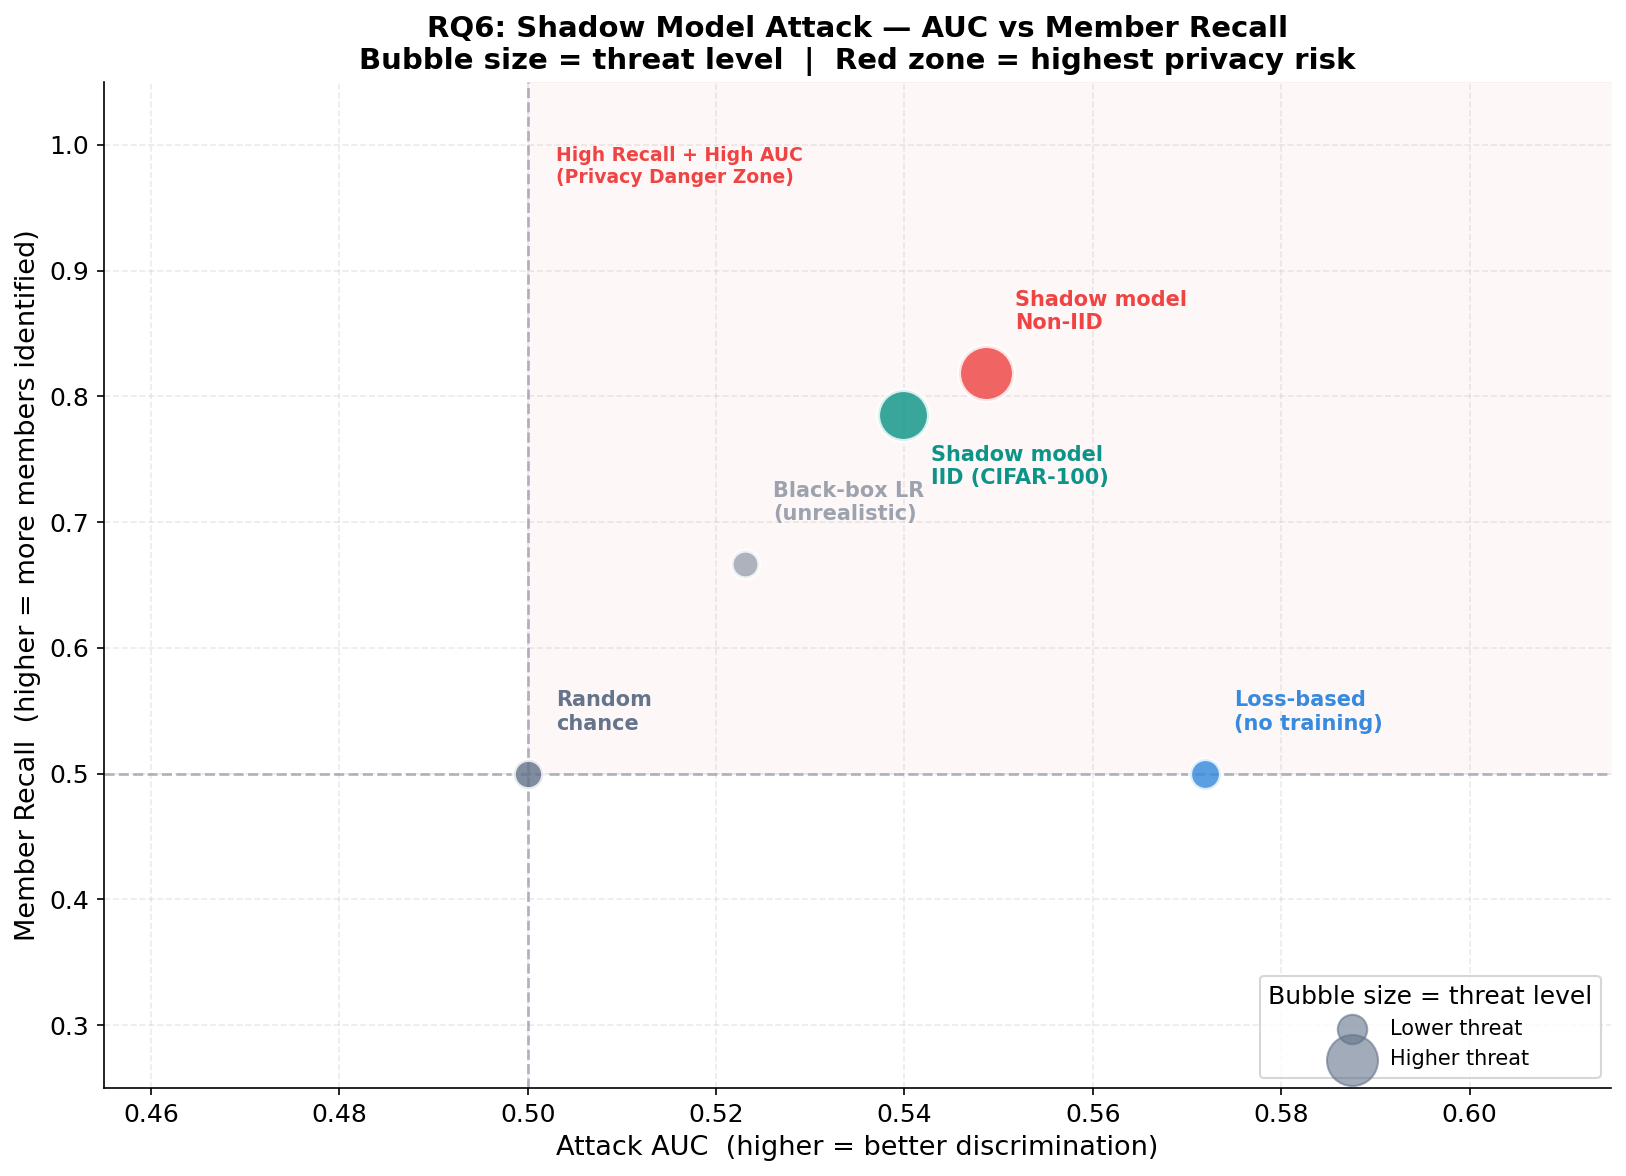

Shadow IID — AUC: 0.5398  Recall: 0.7854
Shadow Non-IID — AUC: 0.5487  Recall: 0.8186
Unrealistic baseline — AUC: 0.5230  Recall: 0.6667


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 12,
    'axes.titlesize': 14, 'axes.titleweight': 'bold',
    'axes.labelsize': 12, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True,
    'grid.alpha': 0.25, 'grid.linestyle': '--',
    'figure.dpi': 150, 'savefig.dpi': 150,
    'savefig.bbox': 'tight', 'savefig.facecolor': 'white',
})
TEAL='#0D9488'; NAVY='#0D1B2A'; BLUE='#378ADD'
RED='#EF4444'; GOLD='#F59E0B'; SLATE='#64748B'; GREEN='#16A34A'
RANDOM_LINE = dict(color='#9CA3AF', linestyle='--', linewidth=1.4, label='Random chance (0.50)')

# ── Figure 1: Bubble chart — AUC vs Recall ───────────────────────────────────
# This is the showpiece figure for the shadow model section
attack_names   = ['Random\nchance', 'Black-box LR\n(unrealistic)', 'Loss-based\n(no training)',
                  'Shadow model\nIID (CIFAR-100)', 'Shadow model\nNon-IID']
bubble_aucs    = [0.500, base_metrics["auc"], loss_auc,
                  shadow_attack_metrics["auc"], noniid_shadow_metrics["auc"]]
bubble_recalls = [0.500, base_metrics["recall"], 0.500,
                  shadow_attack_metrics["recall"], noniid_shadow_metrics["recall"]]
bubble_sizes   = [200, 180, 220, 600, 700]
bubble_colors  = [SLATE, "#9CA3AF", BLUE, TEAL, RED]

fig, ax = plt.subplots(figsize=(11, 8))
for i, (name, auc, rec, sz, col) in enumerate(
        zip(attack_names, bubble_aucs, bubble_recalls, bubble_sizes, bubble_colors)):
    ax.scatter(auc, rec, s=sz, color=col, alpha=0.82,
               edgecolors='white', linewidth=2, zorder=4)
    offset_y = 0.035 if i != 3 else -0.055
    ax.annotate(name, (auc, rec),
                xytext=(auc + 0.003, rec + offset_y),
                fontsize=10, fontweight='bold', color=col)

ax.axvline(0.50, color='#9CA3AF', linestyle='--', linewidth=1.3, alpha=0.8)
ax.axhline(0.50, color='#9CA3AF', linestyle='--', linewidth=1.3, alpha=0.8)
ax.fill_between([0.50, 0.62], [0.50, 0.50], [1.05, 1.05], alpha=0.04, color=RED)
ax.text(0.503, 0.97, 'High Recall + High AUC\n(Privacy Danger Zone)',
        ha='left', fontsize=9, color=RED, fontweight='bold')
ax.set_xlabel('Attack AUC  (higher = better discrimination)', fontsize=13)
ax.set_ylabel('Member Recall  (higher = more members identified)', fontsize=13)
ax.set_title('RQ6: Shadow Model Attack — AUC vs Member Recall\nBubble size = threat level  |  Red zone = highest privacy risk',
             fontsize=14, fontweight='bold')
ax.set_xlim(0.455, 0.615)
ax.set_ylim(0.25, 1.05)
for sz, label in [(200, 'Lower threat'), (600, 'Higher threat')]:
    ax.scatter([], [], s=sz, color=SLATE, alpha=0.6, label=label)
ax.legend(fontsize=10, loc='lower right', title='Bubble size = threat level')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'shadow_iid_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Shadow IID — AUC: {shadow_attack_metrics['auc']:.4f}  Recall: {shadow_attack_metrics['recall']:.4f}")
print(f"Shadow Non-IID — AUC: {noniid_shadow_metrics['auc']:.4f}  Recall: {noniid_shadow_metrics['recall']:.4f}")
print(f"Unrealistic baseline — AUC: {base_metrics['auc']:.4f}  Recall: {base_metrics['recall']:.4f}")


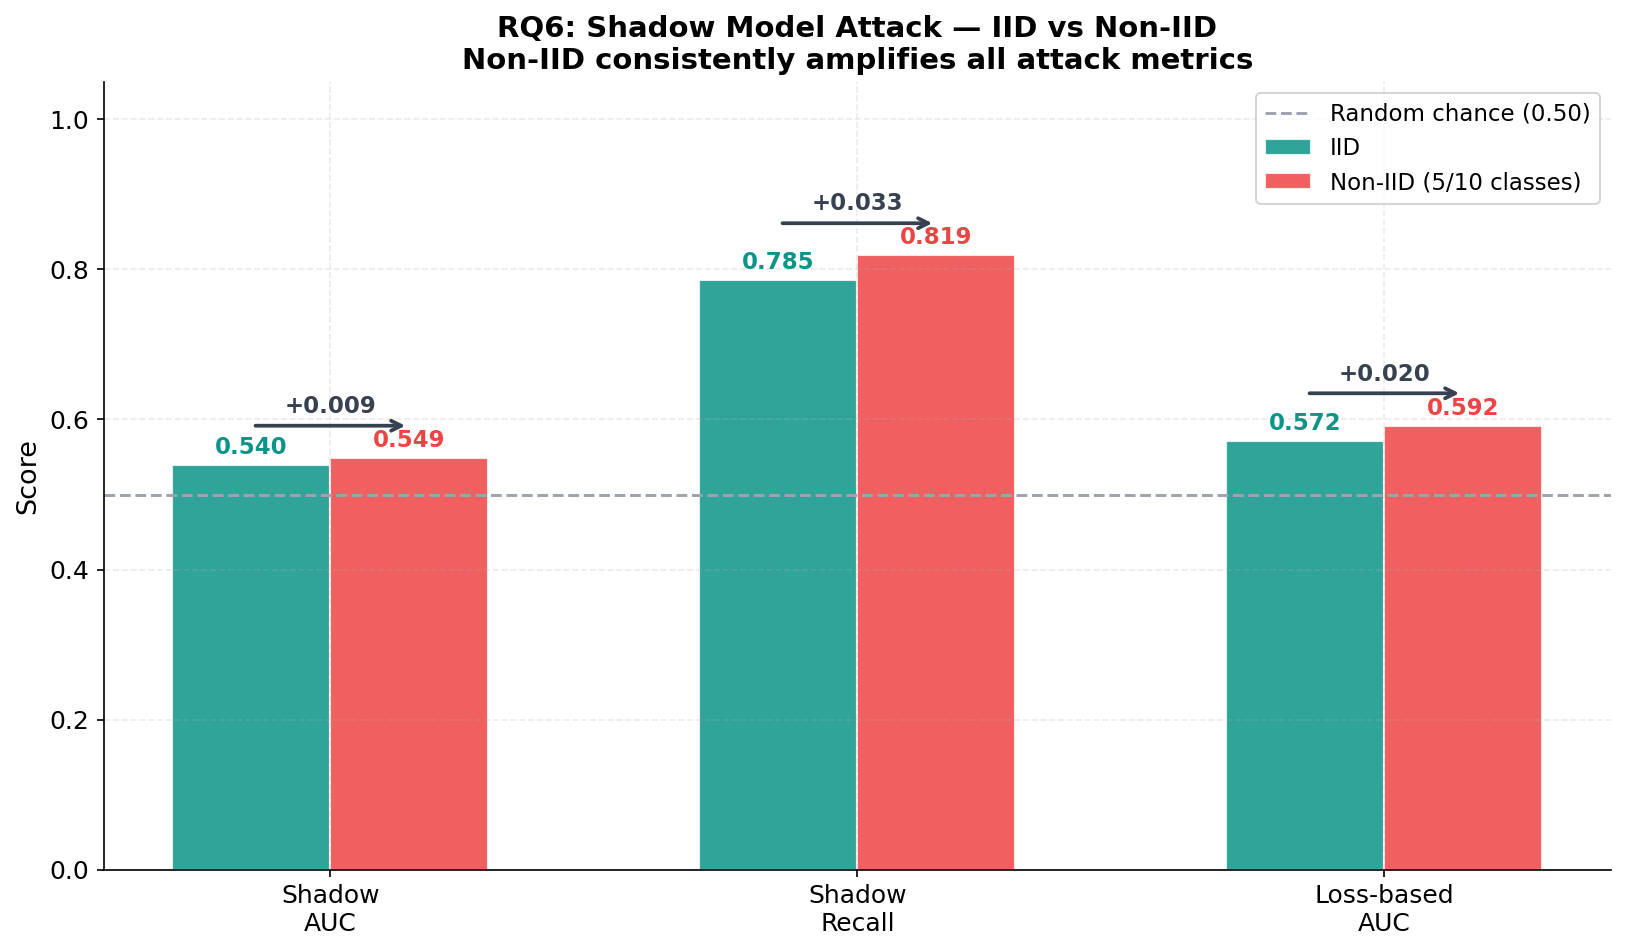

In [ ]:

# ── Figure 2: IID vs Non-IID annotated grouped bar ───────────────────────────
metrics_list = ['Shadow\nAUC', 'Shadow\nRecall', 'Loss-based\nAUC']
iid_vals     = [shadow_attack_metrics["auc"],    shadow_attack_metrics["recall"],    loss_auc]
noniid_vals  = [noniid_shadow_metrics["auc"],    noniid_shadow_metrics["recall"],    noniid_loss_auc]
deltas       = [n - i for n, i in zip(noniid_vals, iid_vals)]

x = np.arange(len(metrics_list))
w = 0.30
fig, ax = plt.subplots(figsize=(11, 6.5))
b1 = ax.bar(x - w/2, iid_vals,    w, color=TEAL, alpha=0.85, label='IID',     edgecolor='white')
b2 = ax.bar(x + w/2, noniid_vals, w, color=RED,  alpha=0.85, label='Non-IID (5/10 classes)', edgecolor='white')

for bar, v in zip(b1, iid_vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.008,
            f'{v:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold', color=TEAL)
for bar, v in zip(b2, noniid_vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.008,
            f'{v:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold', color=RED)

for i, delta in enumerate(deltas):
    y_top = max(iid_vals[i], noniid_vals[i]) + 0.055
    ax.annotate('', xy=(x[i]+w/2, y_top-0.012), xytext=(x[i]-w/2, y_top-0.012),
                arrowprops=dict(arrowstyle='->', color='#374151', lw=1.8))
    sign = '+' if delta > 0 else ''
    ax.text(x[i], y_top + 0.005, f'{sign}{delta:.3f}',
            ha='center', fontsize=11, color='#374151', fontweight='bold')

ax.axhline(0.50, **RANDOM_LINE)
ax.set_xticks(x); ax.set_xticklabels(metrics_list, fontsize=12)
ax.set_ylabel('Score', fontsize=13)
ax.set_title('RQ6: Shadow Model Attack — IID vs Non-IID\nNon-IID consistently amplifies all attack metrics',
             fontsize=14, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'shadow_noniid_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
# ── Step 10: Final Summary & Save Results ─────────────────────────────────────

print('═' * 65)
print('COMPLETE SHADOW MODEL ATTACK SUMMARY')
print('═' * 65)
print(f'  Target FL model (CIFAR-10, IID):      acc = {target_global_acc:.4f}')
print(f'  Shadow FL model (CIFAR-100):          acc = {shadow_global_acc:.4f}')
print()
print(f'  {"Method":<40} {"AUC":>8} {"Recall":>8}')
print(f'  {"-"*56}')
print(f'  {"Unrealistic baseline (real data)":<40} {base_metrics["auc"]:>8.4f} {base_metrics["recall"]:>8.4f}')
print(f'  {"Shadow model attack — IID target":<40} {shadow_attack_metrics["auc"]:>8.4f} {shadow_attack_metrics["recall"]:>8.4f}')
print(f'  {"Shadow model attack — Non-IID target":<40} {noniid_shadow_metrics["auc"]:>8.4f} {noniid_shadow_metrics["recall"]:>8.4f}')
print(f'  {"Loss-based attack — IID":<40} {loss_auc:>8.4f} {"N/A":>8}')
print(f'  {"Loss-based attack — Non-IID":<40} {noniid_loss_auc:>8.4f} {"N/A":>8}')
print(f'  {"Random chance":<40} {0.5000:>8.4f} {0.5000:>8.4f}')
print('═' * 65)
print()
delta_iid    = shadow_attack_metrics['auc'] - base_metrics['auc']
delta_noniid = noniid_shadow_metrics['auc'] - shadow_attack_metrics['auc']
print(f'  Gap: Shadow vs Unrealistic (IID):   {delta_iid:+.4f}')
print(f'  Gap: Non-IID vs IID (shadow):       {delta_noniid:+.4f}')

# Save results to JSON
results = {
    'target_global_acc_iid':     float(target_global_acc),
    'target_global_acc_noniid':  float(noniid_global_acc),
    'shadow_global_acc':         float(shadow_global_acc),
    'unrealistic_auc':           float(base_metrics['auc']),
    'unrealistic_recall':        float(base_metrics['recall']),
    'shadow_auc_iid':            float(shadow_attack_metrics['auc']),
    'shadow_recall_iid':         float(shadow_attack_metrics['recall']),
    'shadow_auc_noniid':         float(noniid_shadow_metrics['auc']),
    'shadow_recall_noniid':      float(noniid_shadow_metrics['recall']),
    'loss_auc_iid':              float(loss_auc),
    'loss_auc_noniid':           float(noniid_loss_auc),
    'delta_shadow_vs_unrealistic': float(delta_iid),
    'delta_noniid_vs_iid':         float(delta_noniid),
}

with open(os.path.join(OUTPUT_DIR, 'shadow_model_results.json'), 'w') as f:
    json.dump(results, f, indent=2)

print()
print('Results saved to shadow_model_results.json')

═════════════════════════════════════════════════════════════════
COMPLETE SHADOW MODEL ATTACK SUMMARY
═════════════════════════════════════════════════════════════════
  Target FL model (CIFAR-10, IID):      acc = 0.7246
  Shadow FL model (CIFAR-100):          acc = 0.3841

  Method                                        AUC   Recall
  --------------------------------------------------------
  Unrealistic baseline (real data)           0.5230   0.6667
  Shadow model attack — IID target           0.5398   0.7854
  Shadow model attack — Non-IID target       0.5487   0.8186
  Loss-based attack — IID                    0.5720      N/A
  Loss-based attack — Non-IID                0.5919      N/A
  Random chance                              0.5000   0.5000
═════════════════════════════════════════════════════════════════

  Gap: Shadow vs Unrealistic (IID):   +0.0168
  Gap: Non-IID vs IID (shadow):       +0.0089

Results saved to shadow_model_results.json


In [ ]:
# ── Download outputs ──────────────────────────────────────────────────────────
from google.colab import files
files.download(os.path.join(OUTPUT_DIR, 'shadow_iid_comparison.png'))
files.download(os.path.join(OUTPUT_DIR, 'shadow_noniid_comparison.png'))
files.download(os.path.join(OUTPUT_DIR, 'shadow_model_results.json'))
print('Done! Run Notebook 06 next for the white-box attack.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done! Run Notebook 06 next for the white-box attack.
